# 07 · 第三课：预训练与继续预训练

上一课我们固定权重做推理；这一课让参数真正更新，观察它怎样学会预测下一 token。

我们手里有：已经理解的 Qwen 结构、06 的书籍清洗方法、PyTorch 的自动求导。现在要接上的链条是：**文本怎样自动产生 labels → loss 怎样衡量错误 → 梯度怎样更新参数 → 保存后怎样继续学**。

主课用约十万参数的 **Qwen3 小配置**，在 CPU 上训练几百步，适合 16 GB Mac。调用同一套 Transformers Qwen3 类，但从随机参数开始，**没有加载上一课的 0.6B 权重，也不是对官方 Qwen 做继续预训练**。这里的“继续预训练”是加载我们自己训练出的模型 A，继续学习另一批文本 B。

先看图和实际输出，再逐格拆解；不安排填空或 homework。保存的运行输出属于教师验证，不算用户已完成训练。

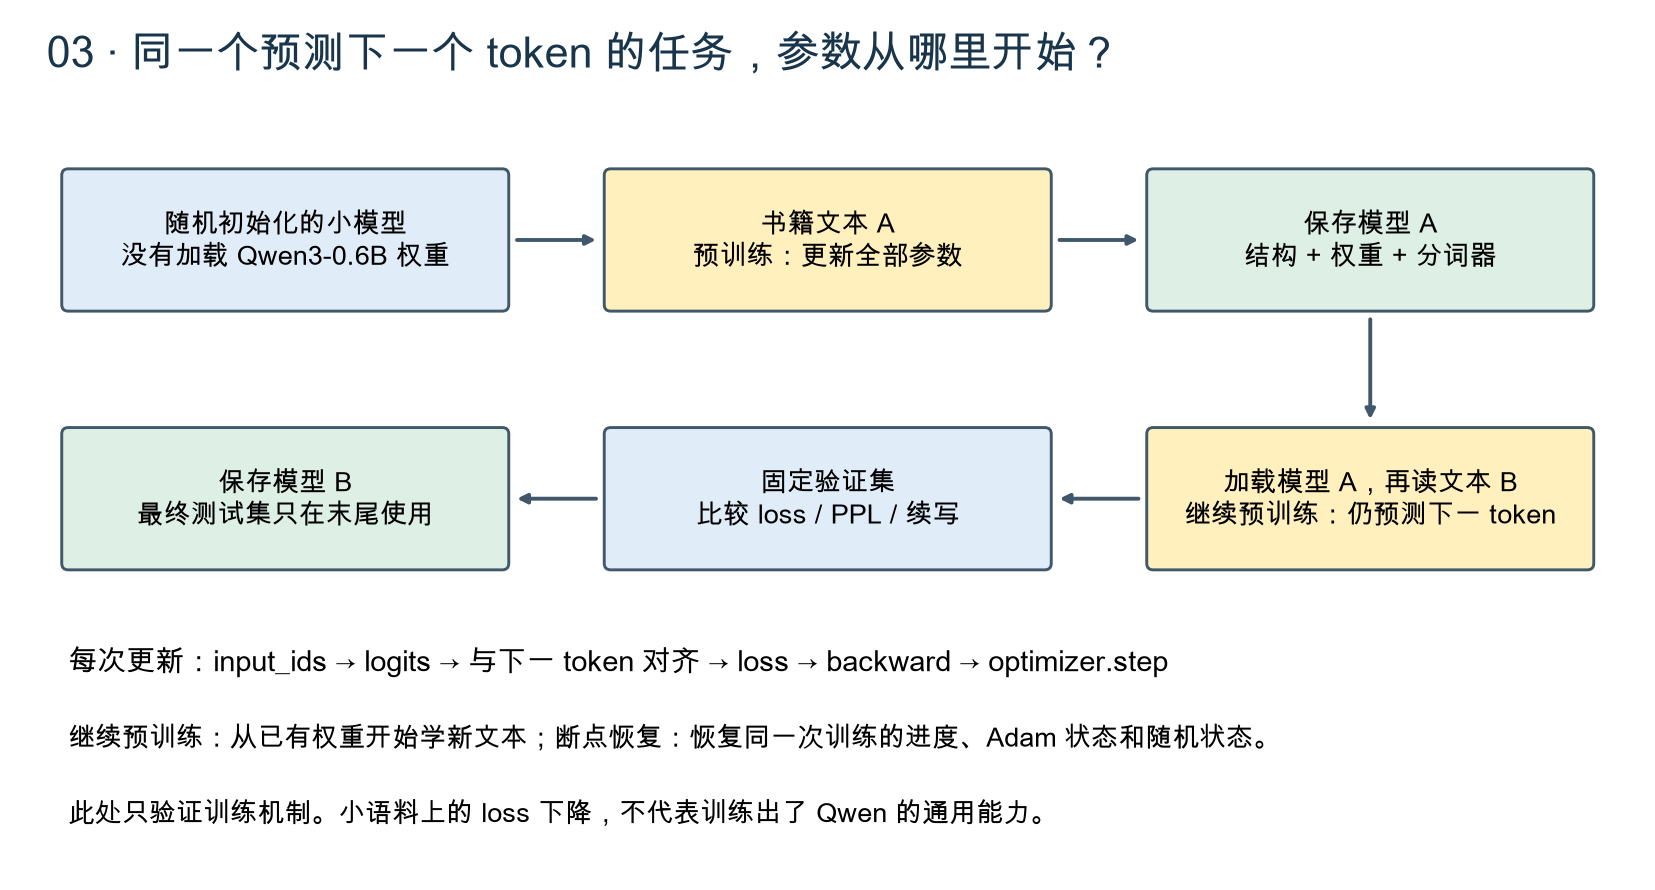

## 0 · 环境与实验规模

仓库根目录执行 `uv sync --extra inference`，选择项目 `.venv` 内核。本课使用上一课安装的 Transformers，不需要下载模型、租 GPU 或调用 API。

默认 CPU、2 线程、float32、固定种子、无 dropout。这个小实验优先让训练和断点恢复容易检查。若上一课的 0.6B 模型还在另一个内核里，可先关闭那个内核以释放内存。本课的模型、Adam 和随机状态保存在被 Git 忽略的 `artifacts/` 中。

In [1]:
from pathlib import Path
from datetime import datetime
import sys, json, math, time, hashlib
import torch
import transformers
from transformers import Qwen3ForCausalLM
from IPython.display import display
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'07-modern-llm').is_dir())
LESSON = ROOT/'07-modern-llm'/'03-pretraining'
sys.path.insert(0, str(LESSON))
from training_lab import (load_assets, new_model, windows, collate, batch_for, manual_loss,
                          evaluate, train_steps, save_resume, load_resume, completion, tokenizer_hash)
torch.set_num_threads(2)
ARTIFACTS = LESSON/'artifacts'
ARTIFACTS.mkdir(exist_ok=True)
print('Python:', sys.executable)
print('设备: CPU | torch:', torch.__version__, '| transformers:', transformers.__version__)

Python: /Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/.venv/bin/python
设备: CPU | torch: 2.14.1 | transformers: 4.57.3


## 1 · 没有人工标签，书籍怎么训练？

文本自身给出答案。例如 `Alice was beginning`，模型看到 `Alice` 后，真实下一个 token 来自原文，不需要人工标注“类别”。实际 BPE token 不一定是一整个单词，下面直接查看真实 ID。

语料来自 Project Gutenberg 的《Alice’s Adventures in Wonderland》英语原文。复用 06 的去重、段落划分规则，固定选取 120 段 A、另一处 120 段 B、24 段验证、24 段测试。**先按完整段落划分，再切窗口**，不会把同一个段落的重叠窗口随机分进训练和验证。

A/B 来自同一本书，用来观察“新一批文本继续学习”，不是跨行业迁移实验。分词器只在 A 上训练一次，512 词表的 byte-level BPE，B 阶段保持不变。原文来源、选择规则和 SHA256 见 `assets/source.json`。

In [2]:
corpus, tokenizer = load_assets()
source = json.loads((LESSON/'assets/source.json').read_text())
print('来源:', source['source'])
for name, paragraphs in corpus.items():
    print(name, '段落数:', len(paragraphs))
print('\nA 的一段真实文本：', corpus['train_a'][1])
print('\nB 的一段真实文本：', corpus['train_b'][1])
print('词表大小:', tokenizer.get_vocab_size())
samples = {name: windows(paragraphs, tokenizer, length=64) for name, paragraphs in corpus.items()}
print('窗口数:', {name:len(rows) for name,rows in samples.items()})

来源: https://www.gutenberg.org/ebooks/11
train_a 段落数: 120
train_b 段落数: 120
validation 段落数: 24
test 段落数: 24

A 的一段真实文本： So she was considering in her own mind (as well as she could, for the hot day made her feel very sleepy and stupid), whether the pleasure of making a daisy-chain would be worth the trouble of getting up and picking the daisies, when suddenly a White Rabbit with pink eyes ran close by her.

B 的一段真实文本： Alice considered a little, and then said “The fourth.”
词表大小: 512
窗口数: {'train_a': 327, 'train_b': 187, 'validation': 45, 'test': 45}


## 2 · 一次训练，预测多个位置

每个窗口最多取 65 个 ID，提供最多 64 个“下一个 token”目标。段落开头加入 BOS、真实段落结尾加入 EOS；任意窗口边界不伪装成文章结束。最后不足长度的窗口保留，通过 padding 组成 batch。

**本课与 06 的代码接口有一个重要差别：**

| 实现 | 传给 loss 的 labels |
|---|---|
| 06 自己调用交叉熵 | 自己先错开一位：`x=ids[:-1]`，`y=ids[1:]` |
| 本课 HF `model(..., labels=labels)` | `labels=input_ids.clone()`，内部自动错开一位 |

不能同时做两次错位。我们将 padding 对应的 labels 改成 `-100`，表示“不计算这个目标的 loss”。`attention_mask=0` 则用于遮挡 padding key，两者职责不同。

In [3]:
# 用一长一短两条真实窗口，确保能看到 padding。
short = min(samples['train_a'], key=len)
long = max(samples['train_a'], key=len)
batch = collate([long, short])
print('input_ids:', tuple(batch['input_ids'].shape))
print('labels:   ', tuple(batch['labels'].shape))
print('短样本的 attention_mask:', batch['attention_mask'][1].tolist())
print('短样本的 labels:        ', batch['labels'][1].tolist())
print('\n第一个窗口：位置 i 的 logits 要预测位置 i+1 的真实 ID')
for i in range(12):
    current = batch['input_ids'][0,i].item()
    target = batch['labels'][0,i+1].item()
    print(f'i={i:2d} 输入ID={current:3d} {tokenizer.id_to_token(current)!r:14s} → 目标ID={target:3d} {tokenizer.id_to_token(target)!r}')

input_ids: (2, 65)
labels:    (2, 65)
短样本的 attention_mask: [1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
短样本的 labels:         [16, 2, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100, -100]

第一个窗口：位置 i 的 logits 要预测位置 i+1 的真实 ID
i= 0 输入ID=  1 '<BOS>'        → 目标ID= 35 'A'
i= 1 输入ID= 35 'A'            → 目标ID=327 'lice'
i= 2 输入ID=327 'lice'         → 目标ID=311 'Ġwas'
i= 3 输入ID=311 'Ġwas'         → 目标ID=450 'Ġbeg'
i= 4 输入ID=450 'Ġbeg'         → 目标ID=264 'in'
i= 5 输入ID=264 'in'           → 目标ID= 80 'n'
i= 6 输入ID= 80 'n'         

每个位置只允许看自己和左边的 token；虽然一次把整段真实文本送入模型，因果 mask 阻止看到当前位置右边的答案。训练可并行计算各位置的 loss；生成时还没有真实后续 token，才需要逐个生成。

这里使用 teacher forcing：下一位置的输入来自真实文本。PAD 的 ID 是 0，`-100` 只出现在 labels 中，不是一个可输入 Embedding 的 token。

## 3 · 创建随机参数，计算第一次 loss

小模型：2 层、隐藏宽度 64、4 个 Q 头、2 个 KV 头、每头 16 维、SwiGLU 中间宽度 176。调用 `Qwen3ForCausalLM(config)` 创建随机模型；与上一课 `from_pretrained(仓库名)` 加载已有权重不同。

下面用两种方式计算同一个 loss：模型内部自动错位，以及我们手动取 `logits[:,:-1]` 对齐 `labels[:,1:]`。如果两者相同，才能确认“哪个位置预测哪个目标”没有接错。

In [4]:
model = new_model(tokenizer.get_vocab_size())
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)
generator = torch.Generator().manual_seed(2026)
print('参数量:', sum(p.numel() for p in model.parameters()))
print('共享 Embedding / LM head:', model.lm_head.weight is model.model.embed_tokens.weight)
model.train()
output = model(**batch, use_cache=False)
manual = manual_loss(output.logits, batch['labels'])
print('logits:', tuple(output.logits.shape))
print('内置 loss:', output.loss.item(), '| 手动对齐 loss:', manual.item())
torch.testing.assert_close(output.loss, manual)
print('若 512 个 token 完全均匀预测，loss ≈ ln(512) =', math.log(512))

参数量: 125312
共享 Embedding / LM head: True
logits: (2, 65, 512)
内置 loss: 6.28919792175293 | 手动对齐 loss: 6.28919792175293
若 512 个 token 完全均匀预测，loss ≈ ln(512) = 6.238324625039508


交叉熵在每个有效位置取真实目标 token 的概率：`loss_i = -log p(真实下一个 token)`，然后求平均。目标概率变大，该位置 loss 就变小。不需要先取 argmax；argmax 丢掉了概率信息，不能代替这里的训练目标。

困惑度 `PPL = exp(平均loss)`，越低表示模型在这份数据上对真实 token 的预测更好。不同 tokenizer 的 PPL 不宜直接比较，它也不是回答准确率。

## 4 · 一次更新拆成三件事

先记录验证 loss 和随机模型的续写；再观察 `backward()` 与 `optimizer.step()` 的区别。

- `backward()` 计算并累积 `.grad`，还没有修改权重。
- `optimizer.step()` 读取梯度和 Adam 状态，真正修改参数。
- 下一步前 `zero_grad()` 清掉旧梯度，避免无意累积。

Embedding 也在 `model.parameters()` 里，因此一起更新。词表 ID 没变，改变的是 ID 对应的可学习向量。

In [5]:
initial_validation = evaluate(model, samples['validation'])
initial_text = completion(model, tokenizer)
tracked = {'Embedding': model.model.embed_tokens.weight,
           'Wq': model.model.layers[0].self_attn.q_proj.weight,
           'RMSNorm gamma': model.model.layers[0].input_layernorm.weight}
before = {name: p.detach().clone() for name,p in tracked.items()}
optimizer.zero_grad(set_to_none=True)
output.loss.backward()
probe = {}
for name,p in tracked.items():
    unchanged = torch.equal(before[name], p.detach())
    probe[name] = {'gradient_norm': p.grad.norm().item(), 'unchanged_after_backward': unchanged}
    print(name, '| 梯度范数:', p.grad.norm().item(), '| backward后权重未变:', unchanged)
    assert unchanged and p.grad.norm().item() > 0

torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
optimizer.step()
for name,p in tracked.items():
    delta = (p.detach()-before[name]).abs().max().item()
    probe[name]['max_update'] = delta
    print(name, '| step后最大变化:', delta)
    assert delta > 0
print('初始验证 loss:', initial_validation['loss'])
print('随机模型续写:', repr(initial_text))
del output, manual, before  # 释放第一次前向图。

Embedding | 梯度范数: 1.642945408821106 | backward后权重未变: True
Wq | 梯度范数: 0.4677993655204773 | backward后权重未变: True
RMSNorm gamma | 梯度范数: 0.015382848680019379 | backward后权重未变: True
Embedding | step后最大变化: 0.0010008662939071655
Wq | step后最大变化: 0.0010006874799728394
RMSNorm gamma | step后最大变化: 0.0010100007057189941
初始验证 loss: 6.2392502766783515
随机模型续写: 'Alice was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was'


## 5 · 预训练 A：重复同一个更新流程

刚才已经做了第 1 次更新，接下来再训练 199 步，总共 200 步。每次随机抽 8 个窗口；每 25 步在**同一个未参与梯度更新的验证集**上评估。

工具函数重复执行的核心就是下面这些行，可以在 `training_lab.py` 中逐行查看：

```python
model.train()
optimizer.zero_grad(set_to_none=True)
output = model(**batch, use_cache=False)
output.loss.backward()
torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
optimizer.step()
```

梯度裁剪限制整体梯度范数，避免某一步梯度过大；它不是把参数限制在固定数值范围。

这里的“步”是一次 optimizer 更新，不是完整读遍一轮数据。为了观察机制，使用固定学习率；没有宣称复现 Qwen 官方训练配方。训练时关闭 KV cache，所有位置一起计算 loss。

In [6]:
started = time.perf_counter()
history_a = train_steps(model, optimizer, samples['train_a'], samples['validation'],
                        generator, steps=199, start=1)
validation_a = evaluate(model, samples['validation'])
text_a = completion(model, tokenizer)
print('A阶段后续写:', repr(text_a))
print('A阶段验证:', validation_a)

step= 25  当前batch loss=5.4947  固定验证集loss=5.5024


step= 50  当前batch loss=5.3941  固定验证集loss=5.3079


step= 75  当前batch loss=5.1150  固定验证集loss=5.1839


step=100  当前batch loss=4.8804  固定验证集loss=4.9773


step=125  当前batch loss=4.6688  固定验证集loss=4.7986


step=150  当前batch loss=4.5473  固定验证集loss=4.6609


step=175  当前batch loss=4.3279  固定验证集loss=4.5772


step=200  当前batch loss=4.2729  固定验证集loss=4.4708


A阶段后续写: 'Alice was cooo, and the can, and the cante, and the canttted, and the canted'
A阶段验证: {'loss': 4.470814141748627, 'perplexity': 87.4278727277159, 'target_tokens': 2232}


## 6 · 保存：仅权重与完整训练状态，分别有什么用？

`save_pretrained()` 保存模型结构和权重，可以重新加载并推理，也能作为下一次训练的起点。它不替你保存 Adam 的动量与训练随机状态。

下面另外保存一个恢复文件，包括模型、Adam、步数、抽样随机状态、PyTorch 随机状态，以及分词器哈希。我们的实验限定 CPU、固定语料、单进程、无 dropout、常数学习率；实际训练若有 scheduler、AMP scaler、多卡或 DataLoader worker，还需要保存对应状态。

In [7]:
stage_a = ARTIFACTS/'stage-a'
model.save_pretrained(stage_a)
tokenizer.save(str(stage_a/'tokenizer.json'))
(stage_a/'data-source.json').write_text(json.dumps(source,ensure_ascii=False,indent=2))
save_resume(ARTIFACTS/'resume-a.pt', model, optimizer, generator, step=200)
print('模型与分词器:', stage_a)
print('完整恢复状态:', ARTIFACTS/'resume-a.pt')

模型与分词器: /Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/07-modern-llm/03-pretraining/artifacts/stage-a
完整恢复状态: /Users/yorkchen/文稿 - 陈尧的MacBook Pro/VibeCoding/llm-from-zero/07-modern-llm/03-pretraining/artifacts/resume-a.pt


## 7 · 继续预训练 B：加载已有权重，再学习新文本

这次不是随机初始化。加载模型 A，验证“加载前后相同输入的 loss 一致”，然后使用文本 B 训练 100 步。

我们把它作为**一个新的训练阶段**，明确重新创建 Adam，使用更小的学习率 `3e-4`；分词器和词表不变。继续预训练可以选择保留或重建优化器状态，这里选择重建。断点恢复同一次训练则应该保留原来的状态。

B 仍是书籍正文，目标仍是预测下一 token；没有对话问题/回答格式，也没有只对 assistant 回答计算 loss，因此不是 SFT。

In [8]:
continued = Qwen3ForCausalLM.from_pretrained(stage_a, local_files_only=True,
                                            dtype=torch.float32, attn_implementation='eager')
loaded_validation = evaluate(continued, samples['validation'])
assert abs(loaded_validation['loss']-validation_a['loss']) < 1e-6
print('重新加载前/后验证loss:', validation_a['loss'], loaded_validation['loss'])
optimizer_b = torch.optim.AdamW(continued.parameters(), lr=3e-4, weight_decay=0.01)
generator_b = torch.Generator().manual_seed(2027)
history_b = train_steps(continued, optimizer_b, samples['train_b'], samples['validation'],
                        generator_b, steps=100)
validation_b = evaluate(continued, samples['validation'])
text_b = completion(continued, tokenizer)
continued.save_pretrained(ARTIFACTS/'stage-b')
tokenizer.save(str(ARTIFACTS/'stage-b'/'tokenizer.json'))
save_resume(ARTIFACTS/'resume-b.pt', continued, optimizer_b, generator_b, step=100)
print('B阶段后续写:', repr(text_b))

重新加载前/后验证loss: 4.470814141748627 4.470814141748627


step= 25  当前batch loss=4.1636  固定验证集loss=4.4046


step= 50  当前batch loss=3.9806  固定验证集loss=4.3612


step= 75  当前batch loss=4.0734  固定验证集loss=4.3501


step=100  当前batch loss=3.7383  固定验证集loss=4.3278


B阶段后续写: 'Alice was the The The The The The Hatter the Hatter, and the Hatter, and the H'


## 8 · 看真实曲线，不预设训练一定成功

训练 batch 每次不同，因此 batch loss 会波动。固定验证 loss 更适合比较阶段。训练 loss 下降但验证 loss 上升可能是过拟合；继续预训练也可能损伤旧能力，当前单本书的小验证集不足以评估这种风险。

如果续写仍然重复、拼写奇怪或不成句，保留它：这个小模型、少量文本和短训练只展示更新机制，不保证自然语言质量。不要把“梯度存在”当作“学会语言”，也不要把一条看起来流畅的续写当作整体能力证明。

随机初始化: validation loss=6.2393, PPL=512.47
  相同提示的真实续写: 'Alice was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was was'
预训练A后: validation loss=4.4708, PPL=87.43
  相同提示的真实续写: 'Alice was cooo, and the can, and the cante, and the canttted, and the canted'
继续预训练B后: validation loss=4.3278, PPL=75.78
  相同提示的真实续写: 'Alice was the The The The The The Hatter the Hatter, and the Hatter, and the H'


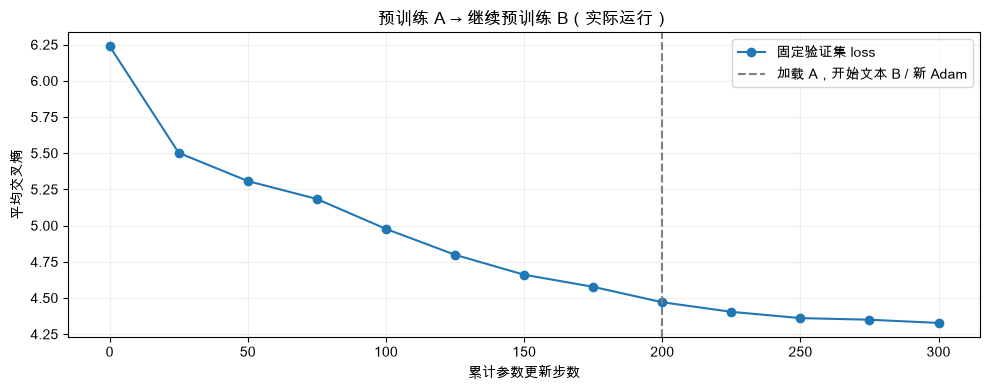

In [9]:
for name, metrics, text in [('随机初始化',initial_validation,initial_text),
                             ('预训练A后',validation_a,text_a),
                             ('继续预训练B后',validation_b,text_b)]:
    print(f"{name}: validation loss={metrics['loss']:.4f}, PPL={metrics['perplexity']:.2f}")
    print('  相同提示的真实续写:', repr(text))
plt.rcParams['font.family']='Arial Unicode MS'
fig,ax=plt.subplots(figsize=(10,4))
xs=[0]+[r['step'] for r in history_a]+[200+r['step'] for r in history_b]
ys=[initial_validation['loss']]+[r['validation_loss'] for r in history_a+history_b]
ax.plot(xs,ys,'o-',label='固定验证集 loss')
ax.axvline(200,color='gray',linestyle='--',label='加载 A，开始文本 B / 新 Adam')
ax.set(xlabel='累计参数更新步数',ylabel='平均交叉熵',title='预训练 A → 继续预训练 B（实际运行）')
ax.legend();ax.grid(alpha=.2);fig.tight_layout()
fig.savefig(LESSON/'assets/loss-curve.png',dpi=150)
plt.show()

## 9 · 断点恢复不是重新加载权重那么简单

这里从 A 的第 200 步出发做一个小验证：同一条路径直接做第 201 步，另一条路径加载完整恢复状态再做第 201 步。两条路径抽到相同 batch，Adam 状态相同，因此在本课 CPU 设置下更新后的参数应该完全相同。

这个验证只检查恢复机制，不用测试集调参，也不把这一步混入上面的 A/B 学习曲线。

In [10]:
from training_lab import train_step
reference_batch = batch_for(samples['train_a'], generator)
train_step(model, optimizer, reference_batch)
restored, restored_optimizer, restored_generator, saved_step = load_resume(ARTIFACTS/'resume-a.pt')
restored_batch = batch_for(samples['train_a'], restored_generator)
assert torch.equal(reference_batch['input_ids'], restored_batch['input_ids'])
train_step(restored, restored_optimizer, restored_batch)
resume_error = max((p-q).abs().max().item() for p,q in zip(model.parameters(), restored.parameters()))
print('恢复点:', saved_step, '| 两条路径第201步后的最大参数误差:', resume_error)
assert resume_error == 0.0

恢复点: 200 | 两条路径第201步后的最大参数误差: 0.0


## 10 · 最后才使用测试集

验证集用于观察训练；测试集留到配置确定后评估。本课固定了 200+100 步，没有用测试结果选择步数。下面只评估最终 B 模型，不根据测试 loss 再修改本次实验。

结果只代表这些留出段落，不代表通用问答、中文或推理能力；下一课 SFT 会另行构造任务数据与评估标准。

In [11]:
test_b = evaluate(continued, samples['test'])
print('最终测试集:', test_b)
report = dict(kind='teacher_execution_not_student_completion',
              executed_at=datetime.now().astimezone().isoformat(), device='cpu',
              torch=torch.__version__, transformers=transformers.__version__,
              architecture='tiny Qwen3 from random initialization, not pretrained Qwen3-0.6B',
              parameters=sum(p.numel() for p in continued.parameters()),
              tokenizer_sha256=tokenizer_hash(), source=source,
              steps_a=200, steps_b=100, gradient_probe=probe,
              validation_initial=initial_validation, validation_a=validation_a, validation_b=validation_b,
              test_b=test_b, history_a=history_a, history_b=history_b,
              generations=dict(initial=initial_text, after_a=text_a, after_b=text_b),
              resume_max_parameter_error=resume_error, elapsed_seconds=time.perf_counter()-started)
(LESSON/'assets/execution-report.json').write_text(json.dumps(report,ensure_ascii=False,indent=2)+'\n')
print('报告已保存；模型文件只保留在本地 artifacts。')

最终测试集: {'loss': 4.204042322151326, 'perplexity': 66.95644424857153, 'target_tokens': 2038}
报告已保存；模型文件只保留在本地 artifacts。


## 换成真实 Qwen 继续预训练，会改变什么？

核心循环仍然是 `model → loss → backward → step`，但起点和资源会改变：

| 本课 | 真正继续预训练 Qwen |
|---|---|
| 随机小配置训练出 A，再加载 A | 加载已有 Base 模型权重与它匹配的 tokenizer |
| 我们训练的 512 词表 tokenizer | 保持原模型 tokenizer / token ID 语义 |
| 几百步、短书籍片段 | 根据新领域语料、验证指标和预算制定训练量 |
| CPU 小规模全参数更新 | 根据序列长度与显存选择 GPU、精度、批量与训练方式 |

上一课加载的是经过后训练的 Qwen3-0.6B 聊天模型；继续学习原始文本可能改变它的指令遵循能力，不能把“loss 下降”当作对话能力提升。学习继续预训练通常先讨论 Base 起点，下一课再讨论 SFT / LoRA。这里没有偷偷对上一课下载的权重执行更新。

16 GB 内存能放下推理权重，不等于全参数训练只需同样内存：还要有梯度、优化器状态、反向传播激活等。GPU 选型需要用明确模型、序列长度和 batch 实测，本课不产生租卡费用。

训练与推理的主要区别：训练使用真实后续 token 作目标、计算梯度并更新 W；推理固定 W，自回归选取新 token。训练阶段通常不用生成时的 KV cache，`use_cache=False` 不会关闭因果 mask。

资料与实现：[原文来源](https://www.gutenberg.org/ebooks/11) · [固定 Transformers 4.57.3 的 CausalLM loss](https://github.com/huggingface/transformers/blob/v4.57.3/src/transformers/loss/loss_utils.py) · 本课 `training_lab.py` · 06 的 `text_pretraining.py`。